# Kondo (2009) — Zebrafish Pigment Turing Patterns
## Reproducing Figure 4: Numerical Verification

**Reference:** Kondo, S. (2009). Interactions between zebrafish pigment cells
responsible for the generation of Turing patterns.
*PNAS* **106**(21), 8429–8434.  doi:10.1073/pnas.0808622106

---

### PDEs solved (128 × 128 grid, Neumann BCs)

$$\frac{\partial u}{\partial t} = F(u,v,w) - c_u\,u + D_u\,\nabla^2 u
  \qquad \text{melanophores}$$

$$\frac{\partial v}{\partial t} = G(u,v,w) - c_v\,v + D_v\,\nabla^2 v
  \qquad \text{xanthophores}$$

$$\frac{\partial w}{\partial t} = H(u,v,w) - c_w\,w + D_w\,\nabla^2 w
  \qquad \text{long-range factor}$$

Production functions are clamped-linear:
$$F = \operatorname{clip}(c_1 v + c_2 w + c_3,\;0,\;U), \quad
  G = \operatorname{clip}(c_4 u + c_5 w + c_6,\;0,\;V), \quad
  H = \operatorname{clip}(c_7 u + c_8 v + c_9,\;0,\;W)$$

### Goals
1. Locate homogeneous steady states and confirm they are **stable** at $k=0$
2. Confirm a **Turing instability** via the dispersion relation $\sigma(k^*)>0$
3. Run full simulations and **reproduce Figure 4**

## Cell 1 — Imports and configuration

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import pandas as pd
import time, sys, os, warnings

sys.path.insert(0, os.path.abspath("."))

from kondo_rd import (
    WILDTYPE, LEOPARD, JAGUAR,
    find_steady_states, interior_steady_state,
    reaction_jacobian, stability_analysis, dispersion_relation,
    simulate, fields_to_rgb, plot_fig4, plot_time_evolution,
    _ode_residual,
)

# ── plotting defaults ─────────────────────────────────────────────────────────
plt.rcParams.update({
    "figure.dpi"       : 120,
    "axes.labelsize"   : 12,
    "axes.titlesize"   : 13,
    "legend.fontsize"  : 10,
    "axes.spines.top"  : False,
    "axes.spines.right": False,
})

ALL_PARAMS = [WILDTYPE, LEOPARD, JAGUAR]
print("✓  Imports OK")
print(f"   Parameter sets loaded: {[p['name'] for p in ALL_PARAMS]}")

✓  Imports OK
   Parameter sets loaded: ['Wild Type', 'Leopard Mutant', 'Jaguar/Obelix Mutant']


## Cell 2 — Parameter comparison table

The three parameter sets differ only in the highlighted entries:
- **Leopard mutant** — $c_3 = 0.385$ (vs. $0.370$ in wild type)
- **Jaguar/Obelix mutant** — $D_u, D_v, D_w$ doubled

In [3]:
PARAM_KEYS = [
    "c1","c2","c3","c4","c5","c6","c7","c8","c9",
    "cu","cv","cw","Du","Dv","Dw","U","V","W",
]

df_params = pd.DataFrame(
    {p["name"]: {k: p[k] for k in PARAM_KEYS} for p in ALL_PARAMS}
)

# Mark entries that differ from wild type
wt_vals = {k: WILDTYPE[k] for k in PARAM_KEYS}

def _fmt(val, key):
    """Bold + star for values that differ from wild type."""
    return f"★ {val}" if val != wt_vals[key] else str(val)

df_display = df_params.copy().astype(object)
for k in PARAM_KEYS:
    for p in [LEOPARD, JAGUAR]:
        if p[k] != wt_vals[k]:
            df_display.loc[k, p["name"]] = f"★ {p[k]}"

print("\n  Parameter comparison  (★ = differs from wild type)\n")
print(df_display.to_string())

print("\n\n  Summary of mutations:")
for p in [LEOPARD, JAGUAR]:
    diffs = {k: (wt_vals[k], p[k]) for k in PARAM_KEYS if p[k] != wt_vals[k]}
    print(f"\n  {p['name']}:")
    for k, (wt_v, mut_v) in diffs.items():
        print(f"    {k:>4s}:  {wt_v}  →  {mut_v}")


  Parameter comparison  (★ = differs from wild type)

   Wild Type Leopard Mutant Jaguar/Obelix Mutant
c1     -0.04          -0.04                -0.04
c2    -0.055         -0.055               -0.055
c3      0.37        ★ 0.385                 0.37
c4     -0.05          -0.05                -0.05
c5       0.0            0.0                  0.0
c6      0.25           0.25                 0.25
c7     0.016          0.016                0.016
c8     -0.03          -0.03                -0.03
c9      0.24           0.24                 0.24
cu      0.02           0.02                 0.02
cv     0.025          0.025                0.025
cw      0.06           0.06                 0.06
Du      0.02           0.02               ★ 0.04
Dv      0.02           0.02               ★ 0.04
Dw       0.2            0.2                ★ 0.4
U        0.5            0.5                  0.5
V        0.5            0.5                  0.5
W        0.5            0.5                  0.5


  Summary of

## Cell 3 — Homogeneous steady states

We solve the ODE fixed-point problem
$$F(u^*,v^*,w^*) = c_u u^*, \quad G = c_v v^*, \quad H = c_w w^*$$
numerically (grid of initial guesses + `scipy.fsolve`) and analytically
(linear-zone system $J\mathbf{x}^* = -\mathbf{c}_0$).

**For the Turing analysis to apply the steady state must lie strictly
inside the linear production zone of all three functions** — otherwise the
Jacobian $J$ is not the correct linearisation.

In [4]:
print("=" * 62)
print("  HOMOGENEOUS STEADY-STATE ANALYSIS")
print("=" * 62)

SS = {}   # interior steady state for each param set

for p in ALL_PARAMS:
    name    = p["name"]
    ss_list = find_steady_states(p)
    ss_int  = interior_steady_state(p)
    SS[name] = ss_int

    print(f"\n  {name}  ({len(ss_list)} fixed point(s) found)")

    for i, ss in enumerate(ss_list):
        resid   = float(np.max(np.abs(_ode_residual(ss, p))))
        fval    = p["c1"]*ss[1] + p["c2"]*ss[2] + p["c3"]
        gval    = p["c4"]*ss[0] + p["c5"]*ss[2] + p["c6"]
        hval    = p["c7"]*ss[0] + p["c8"]*ss[1] + p["c9"]
        in_lin  = (0 < fval < p["U"]) and (0 < gval < p["V"]) and (0 < hval < p["W"])
        flag    = " ← interior (used)" if in_lin else ""
        print(f"    SS #{i+1}: u={ss[0]:.5f}, v={ss[1]:.5f}, w={ss[2]:.5f}"
              f"   |res|={resid:.2e}  in_linear={in_lin}{flag}")

# Verify the selected interior SS for each mutant
print("\n  Verification: selected SS lies in linear zone?")
print(f"  {'Name':<22}  {'F-arg ∈(0,U)':>14}  {'G-arg ∈(0,V)':>14}  {'H-arg ∈(0,W)':>14}")
print("  " + "─"*62)
for p in ALL_PARAMS:
    ss  = SS[p["name"]]
    fv  = p["c1"]*ss[1] + p["c2"]*ss[2] + p["c3"]
    gv  = p["c4"]*ss[0] + p["c5"]*ss[2] + p["c6"]
    hv  = p["c7"]*ss[0] + p["c8"]*ss[1] + p["c9"]
    ok  = lambda v, ub: "✓" if 0 < v < ub else "✗"
    print(f"  {p['name']:<22}  {fv:+.5f} {ok(fv,p['U']):>2}   "
          f"{gv:+.5f} {ok(gv,p['V']):>2}   "
          f"{hv:+.5f} {ok(hv,p['W']):>2}")

  HOMOGENEOUS STEADY-STATE ANALYSIS

  Wild Type  (3 fixed point(s) found)
    SS #1: u=2.58621, v=4.82759, w=2.27586   |res|=2.78e-17  in_linear=True ← interior (used)
    SS #2: u=0.50000, v=9.00000, w=0.00000   |res|=1.39e-17  in_linear=False
    SS #3: u=0.00000, v=10.00000, w=0.00000   |res|=1.26e-19  in_linear=False

  Leopard Mutant  (2 fixed point(s) found)
    SS #1: u=4.13793, v=1.72414, w=4.24138   |res|=5.55e-17  in_linear=True ← interior (used)
    SS #2: u=0.00000, v=10.00000, w=0.00000   |res|=1.26e-19  in_linear=False

  Jaguar/Obelix Mutant  (3 fixed point(s) found)
    SS #1: u=2.58621, v=4.82759, w=2.27586   |res|=2.78e-17  in_linear=True ← interior (used)
    SS #2: u=0.50000, v=9.00000, w=0.00000   |res|=1.39e-17  in_linear=False
    SS #3: u=0.00000, v=10.00000, w=0.00000   |res|=1.26e-19  in_linear=False

  Verification: selected SS lies in linear zone?
  Name                      F-arg ∈(0,U)    G-arg ∈(0,V)    H-arg ∈(0,W)
  ────────────────────────────────────

## Cell 4 — Linear stability at $k = 0$ (Routh–Hurwitz)

The reaction Jacobian at the interior steady state is:
$$J = \begin{pmatrix} -c_u & c_1 & c_2 \\ c_4 & -c_v & c_5 \\ c_7 & c_8 & -c_w \end{pmatrix}$$

For a $3\times3$ system the **Routh–Hurwitz** necessary and sufficient
conditions for all eigenvalues to have negative real part are:
$$p_1 \;=\; -\operatorname{tr}(J) > 0, \qquad
  p_3 \;=\; -\det(J) > 0, \qquad
  p_2 \;=\; \textstyle\sum_{i<j} M_{ij} > 0, \qquad
  p_1 p_2 > p_3$$

In [5]:
print("=" * 62)
print("  LINEAR STABILITY ANALYSIS  —  k = 0")
print("=" * 62)

RH_RESULTS = {}   # keep for later reference

for p in ALL_PARAMS:
    J     = reaction_jacobian(p)
    evals = np.linalg.eigvals(J)

    # Characteristic-polynomial coefficients (monic degree-3)
    p1 = -np.trace(J)
    p3 = -np.linalg.det(J)
    p2 = (J[0,0]*J[1,1] - J[0,1]*J[1,0]
        + J[0,0]*J[2,2] - J[0,2]*J[2,0]
        + J[1,1]*J[2,2] - J[1,2]*J[2,1])

    rh_ok = (p1 > 0) and (p2 > 0) and (p3 > 0) and (p1*p2 > p3)
    RH_RESULTS[p["name"]] = rh_ok

    sep = "─" * 50
    print(f"\n  {p['name']}")
    print(f"  {sep}")
    print(f"  Jacobian J:")
    for row in J:
        print(f"    {np.array2string(row, precision=4, sign='+')}")

    print(f"\n  Eigenvalues of J (k=0):")
    all_neg = True
    for ev in sorted(evals, key=lambda x: x.real):
        re_ok = ev.real < 0
        if not re_ok:
            all_neg = False
        im_str = (f" ± {abs(ev.imag):.6f}i" if abs(ev.imag) > 1e-9 else "")
        print(f"    λ = {ev.real:+.7f}{im_str:<20s}"
              f"  Re(λ) < 0 : {'✓' if re_ok else '✗ UNSTABLE'}")

    print(f"\n  Routh–Hurwitz coefficients:")
    print(f"    p1 = −tr(J)         = {p1:+.7f}   {'> 0 ✓' if p1>0 else '≤ 0 ✗'}")
    print(f"    p2 = Σ(2×2 minors)  = {p2:+.7f}   {'> 0 ✓' if p2>0 else '≤ 0 ✗'}")
    print(f"    p3 = −det(J)        = {p3:+.7f}   {'> 0 ✓' if p3>0 else '≤ 0 ✗'}")
    print(f"    p1·p2 = {p1*p2:+.2e},  p3 = {p3:+.2e}  "
          f"  p1·p2 > p3 : {'✓' if p1*p2>p3 else '✗'}")
    print(f"\n  ⟹  Steady state {'STABLE' if rh_ok else 'UNSTABLE'} "
          f"at k=0   {'✓' if rh_ok else '✗'}")

  LINEAR STABILITY ANALYSIS  —  k = 0

  Wild Type
  ──────────────────────────────────────────────────
  Jacobian J:
    [-0.02  -0.04  -0.055]
    [-0.05  -0.025 +0.   ]
    [+0.016 -0.03  -0.06 ]

  Eigenvalues of J (k=0):
    λ = -0.0817180                      Re(λ) < 0 : ✓
    λ = -0.0116410 ± 0.006475i          Re(λ) < 0 : ✓
    λ = -0.0116410 ± 0.006475i          Re(λ) < 0 : ✓

  Routh–Hurwitz coefficients:
    p1 = −tr(J)         = +0.1050000   > 0 ✓
    p2 = Σ(2×2 minors)  = +0.0020800   > 0 ✓
    p3 = −det(J)        = +0.0000145   > 0 ✓
    p1·p2 = +2.18e-04,  p3 = +1.45e-05    p1·p2 > p3 : ✓

  ⟹  Steady state STABLE at k=0   ✓

  Leopard Mutant
  ──────────────────────────────────────────────────
  Jacobian J:
    [-0.02  -0.04  -0.055]
    [-0.05  -0.025 +0.   ]
    [+0.016 -0.03  -0.06 ]

  Eigenvalues of J (k=0):
    λ = -0.0817180                      Re(λ) < 0 : ✓
    λ = -0.0116410 ± 0.006475i          Re(λ) < 0 : ✓
    λ = -0.0116410 ± 0.006475i          Re(λ) < 0 :

## Cell 5 — Dispersion relation and Turing-instability check

With diffusion, each spatial Fourier mode $k$ evolves at the rate:
$$\sigma(k) = \max_j \operatorname{Re}\!\left[
    \lambda_j\!\left(J - k^2 \operatorname{diag}(D_u,D_v,D_w)\right)\right]$$

**Turing instability** requires $\sigma(0)<0$ **and** $\sigma(k^*)>0$ for
some $k^*>0$: the homogeneous state is stable without diffusion but
diffusion destabilises a narrow band of modes near $k^*$.

The dominant wavelength is $\lambda^* = 2\pi/k^*$.

In [6]:
print("=" * 62)
print("  TURING INSTABILITY CHECK — FULL DISPERSION RELATION")
print("=" * 62)

DISP = {}  # dispersion-relation results keyed by name

for p in ALL_PARAMS:
    res = stability_analysis(p, verbose=True)
    DISP[p["name"]] = res

# ── compact summary ───────────────────────────────────────────────────────────
print("\n\n  SUMMARY")
row_fmt = "  {:<22s} {:>10s} {:>8s} {:>8s} {:>9s} {:>12s}"
print(row_fmt.format("Name", "SS stable", "Turing", "k*", "λ*", "σ*"))
print("  " + "─"*65)
for p in ALL_PARAMS:
    r = DISP[p["name"]]
    ks  = f"{r['k_peak']:.4f}"  if r["k_peak"]  else "—"
    ls  = f"{r['lam_dom']:.2f}" if r["lam_dom"] else "—"
    ss  = f"{r['s_peak']:.6f}"  if r["s_peak"]  else "—"
    print(row_fmt.format(
        p["name"],
        "yes ✓" if r["stable"] else "NO ✗",
        "yes ✓" if r["turing"] else "no",
        ks, ls, ss,
    ))

# ── estimated time to form patterns from 1 % noise ───────────────────────────
print("\n  Estimated pattern-formation time from 1 % noise  (t ≈ ln(100)/σ*)")
for p in ALL_PARAMS:
    r = DISP[p["name"]]
    if r["s_peak"]:
        t_est = np.log(100.0) / r["s_peak"]
        print(f"    {p['name']:<22s}  σ* = {r['s_peak']:.6f}  "
              f"→  t_form ≈ {t_est:.0f}  (nonlinear saturation requires ×5–10 more)")
    else:
        print(f"    {p['name']:<22s}  no Turing instability detected")

  TURING INSTABILITY CHECK — FULL DISPERSION RELATION

────────────────────────────────────────────────────
  Wild Type
────────────────────────────────────────────────────
  k=0 eigenvalues:        -0.08172,  -0.01164+0.00648j,  -0.01164-0.00648j
  Homogeneous SS stable:  YES ✓
  Turing instability:     YES ✓
  Unstable k-band: k ∈ (0.2612, 0.8862)
  Dominant mode:   k* = 0.5487
  Dom. wavelength: λ* = 11.45 grid units
  Peak growth:     σ* = 0.004556 / time-unit

────────────────────────────────────────────────────
  Leopard Mutant
────────────────────────────────────────────────────
  k=0 eigenvalues:        -0.08172,  -0.01164+0.00648j,  -0.01164-0.00648j
  Homogeneous SS stable:  YES ✓
  Turing instability:     YES ✓
  Unstable k-band: k ∈ (0.2612, 0.8862)
  Dominant mode:   k* = 0.5487
  Dom. wavelength: λ* = 11.45 grid units
  Peak growth:     σ* = 0.004556 / time-unit

────────────────────────────────────────────────────
  Jaguar/Obelix Mutant
──────────────────────────────────

## Cell 6 — Dispersion relation plots

Plots $\sigma(k)$ for all three parameter sets.  
The **shaded region** is the Turing-unstable band; the **orange dot** marks
the dominant mode $k^*$.

/tmp/ipykernel_280/3327674515.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


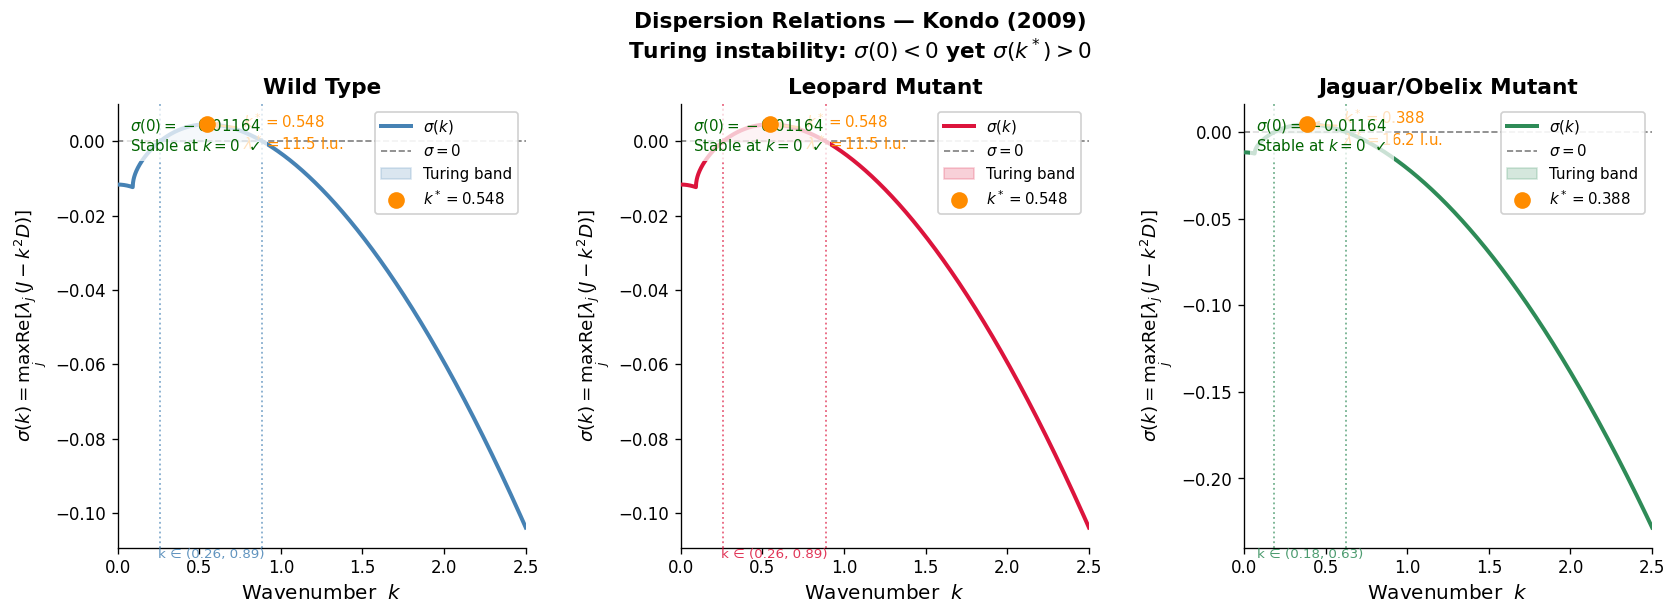

Dispersion plot saved to  dispersion_kondo2009.png


In [7]:
def plot_dispersion_all(param_list, k_max=2.5, n_k=3000,
                        figsize=None, save_path=None):
    """
    Complete replacement for the cut-off helper version.
    Plot σ(k) for each parameter set with Turing-band shading.
    """
    n = len(param_list)
    if figsize is None:
        figsize = (5.5 * n, 4.8)

    colours = ["steelblue", "crimson", "seagreen"][:n]
    fig, axes = plt.subplots(1, n, figsize=figsize,
                             gridspec_kw={"wspace": 0.38})
    if n == 1:
        axes = [axes]

    for ax, p, col in zip(axes, param_list, colours):
        k, sigma = dispersion_relation(p, k_max=k_max, n_k=n_k)

        # main dispersion curve
        ax.plot(k, sigma, color=col, lw=2.4, zorder=3, label=r"$\sigma(k)$")
        ax.axhline(0.0, color="black", lw=1.0, ls="--", alpha=0.5,
                   label=r"$\sigma = 0$")

        # Turing-unstable band (k > 0, σ > 0)
        pos = (sigma > 0) & (k > 0)
        if np.any(pos):
            ax.fill_between(k, 0.0, sigma, where=pos,
                            color=col, alpha=0.20, zorder=2,
                            label="Turing band")
            k_lo = float(k[pos][0])
            k_hi = float(k[pos][-1])
            ax.axvline(k_lo, color=col, lw=1.1, ls=":", alpha=0.65)
            ax.axvline(k_hi, color=col, lw=1.1, ls=":", alpha=0.65)

            # dominant wavenumber
            idx_pk = int(np.argmax(np.where(k > 0, sigma, -np.inf)))
            k_pk   = float(k[idx_pk])
            s_pk   = float(sigma[idx_pk])
            lam_pk = 2.0 * np.pi / k_pk

            ax.plot(k_pk, s_pk, "o", color="darkorange",
                    ms=9, zorder=6, label=f"$k^*={k_pk:.3f}$")
            ax.annotate(
                f"$k^*={k_pk:.3f}$\n$\\lambda^*={lam_pk:.1f}$ l.u.",
                xy=(k_pk, s_pk), xytext=(k_pk + 0.22, s_pk * 0.5),
                fontsize=9, color="darkorange",
                arrowprops=dict(arrowstyle="->",
                                color="darkorange", lw=1.3),
                va="center",
            )
            # band extent label along x-axis
            ax.text((k_lo + k_hi) / 2,
                    ax.get_ylim()[0] if ax.get_ylim()[0] < 0 else -abs(sigma.min())*0.02,
                    f"k ∈ ({k_lo:.2f}, {k_hi:.2f})",
                    ha="center", va="top", fontsize=8,
                    color=col, alpha=0.85)

        # k=0 stability annotation
        s0      = float(sigma[0])
        stab_ok = s0 < 0
        ax.text(0.03, 0.97,
                f"$\\sigma(0) = {s0:.5f}$\n"
                f"{'Stable' if stab_ok else 'UNSTABLE'} at $k=0$  "
                f"{'✓' if stab_ok else '✗'}",
                transform=ax.transAxes, va="top", ha="left", fontsize=9,
                color="darkgreen" if stab_ok else "red",
                bbox=dict(fc="white", ec="none", alpha=0.75))

        ax.set_xlim(0, k_max)
        ax.set_xlabel(r"Wavenumber  $k$", fontsize=12)
        ax.set_ylabel(r"$\sigma(k) = \max_j \mathrm{Re}[\lambda_j(J - k^2 D)]$",
                      fontsize=11)
        ax.set_title(p["name"], fontsize=13, fontweight="bold")
        ax.legend(loc="upper right", fontsize=9, framealpha=0.90)

    fig.suptitle(
        "Dispersion Relations — Kondo (2009)\n"
        r"Turing instability: $\sigma(0)<0$ yet $\sigma(k^*)>0$",
        fontsize=13, fontweight="bold", y=1.04,
    )
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig


fig_disp = plot_dispersion_all(ALL_PARAMS, save_path="dispersion_kondo2009.png")
plt.show()
print("Dispersion plot saved to  dispersion_kondo2009.png")

## Cell 7 — Wild-type simulation

**CFL safety check:**
$\Delta t \leq \frac{1}{4 D_{\max}}$

| Variant | $D_w$ | CFL limit | $\Delta t$ used |
|---------|-------|-----------|----------------|
| Wild type | 0.20 | 1.250 | 0.5 ✓ |
| Leopard   | 0.20 | 1.250 | 0.5 ✓ |
| Jaguar    | 0.40 | 0.625 | 0.5 ✓ |

In [8]:
t0 = time.time()

sim_wt = simulate(
    WILDTYPE,
    n          = 128,
    dt         = 0.5,
    n_steps    = 60_000,   # T_final = 30 000
    save_every = 4_000,    # 16 snapshots (including t=0)
    seed       = 42,
    noise_rel  = 0.01,     # 1 % Gaussian noise around SS
    verbose    = True,
)

print(f"\nWild-type wall time: {time.time() - t0:.1f} s")


════════════════════════════════════════════════════
  Simulating: Wild Type
  Grid 128×128  |  dt=0.5  |  steps=60,000  |  T_final=30000
  CFL limit: dt ≤ 1.250
  Interior SS: u*=2.5862, v*=4.8276, w*=2.2759   (max|res|=2.78e-17)
  Integrating: ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u∈[0.051,6.343]  v∈[0.165,9.722]  w∈[0.512,4.498]

Wild-type wall time: 33.3 s


## Cell 8 — Leopard mutant simulation

In [9]:
t0 = time.time()

sim_leo = simulate(
    LEOPARD,
    n          = 128,
    dt         = 0.5,
    n_steps    = 60_000,
    save_every = 4_000,
    seed       = 42,
    noise_rel  = 0.01,
    verbose    = True,
)

print(f"\nLeopard wall time: {time.time() - t0:.1f} s")


════════════════════════════════════════════════════
  Simulating: Leopard Mutant
  Grid 128×128  |  dt=0.5  |  steps=60,000  |  T_final=30000
  CFL limit: dt ≤ 1.250
  Interior SS: u*=4.1379, v*=1.7241, w*=4.2414   (max|res|=5.55e-17)
  Integrating: ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u∈[0.295,5.964]  v∈[0.037,8.692]  w∈[1.406,5.059]

Leopard wall time: 32.9 s


## Cell 9 — Jaguar / Obelix mutant simulation

In [10]:
t0 = time.time()

sim_jag = simulate(
    JAGUAR,
    n          = 128,
    dt         = 0.5,
    n_steps    = 60_000,
    save_every = 4_000,
    seed       = 42,
    noise_rel  = 0.01,
    verbose    = True,
)

print(f"\nJaguar wall time: {time.time() - t0:.1f} s")

ALL_SIMS = [sim_wt, sim_leo, sim_jag]


════════════════════════════════════════════════════
  Simulating: Jaguar/Obelix Mutant
  Grid 128×128  |  dt=0.5  |  steps=60,000  |  T_final=30000
  CFL limit: dt ≤ 0.625
  Interior SS: u*=2.5862, v*=4.8276, w*=2.2759   (max|res|=2.78e-17)
  Integrating: ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u∈[0.113,6.371]  v∈[0.165,9.445]  w∈[0.635,4.497]

Jaguar wall time: 32.7 s


## Cell 10 — Reproduce Figure 4

Colour scheme (following Kondo 2009):
| Colour | Meaning |
|--------|---------|
| **Green** | high $u$ (melanophores), low $v$ |
| **Blue** | low $u$, high $v$ (xanthophores) |
| **Cyan** | both high |
| **Black** | both low |

Expected results:
- Wild type → stripe pattern
- Leopard → spot pattern (increased $c_3$ raises $u$-production, shifts topology)
- Jaguar → wider stripes (higher $D$ shifts $k^*$ to smaller values → larger $\lambda^*$)

/home/adrianl/projects/turing/kondo/kondo_rd.py:464: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


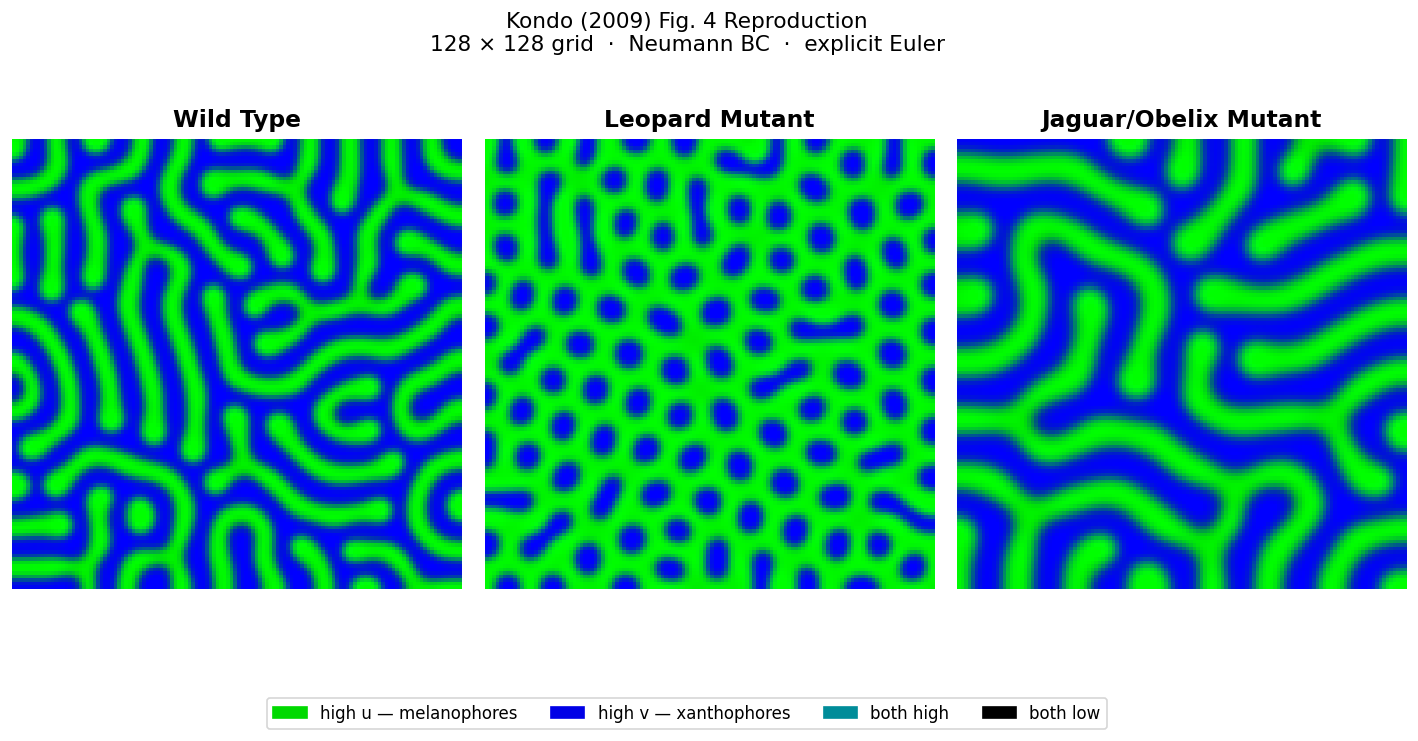

Figure 4 saved to  fig4_kondo2009.png


In [11]:
fig4 = plot_fig4(ALL_SIMS, save_path="fig4_kondo2009.png")
plt.show()
print("Figure 4 saved to  fig4_kondo2009.png")

## Cell 11 — Pattern emergence: time evolution

Six evenly-spaced snapshots from $t=0$ to $t=T_{\rm final}$ for each variant.

/home/adrianl/projects/turing/kondo/kondo_rd.py:484: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


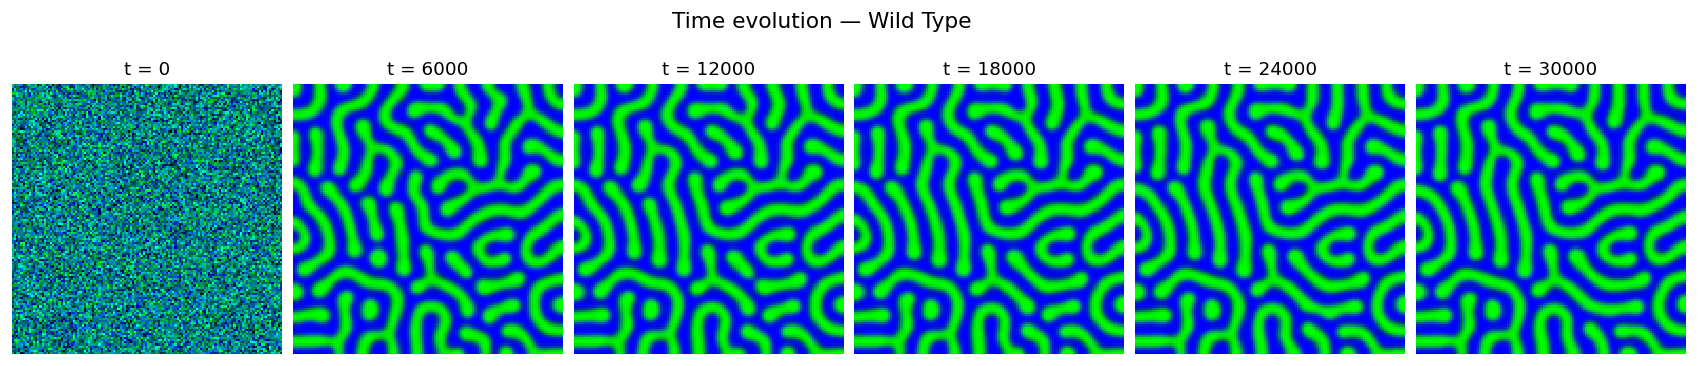

Saved  evolution_wild_type.png


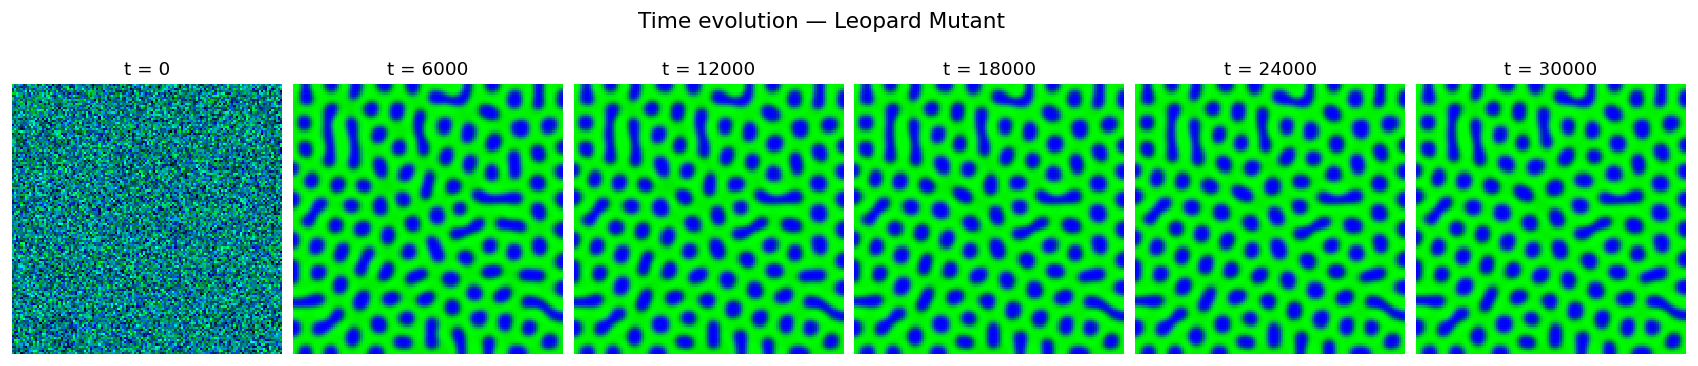

Saved  evolution_leopard_mutant.png


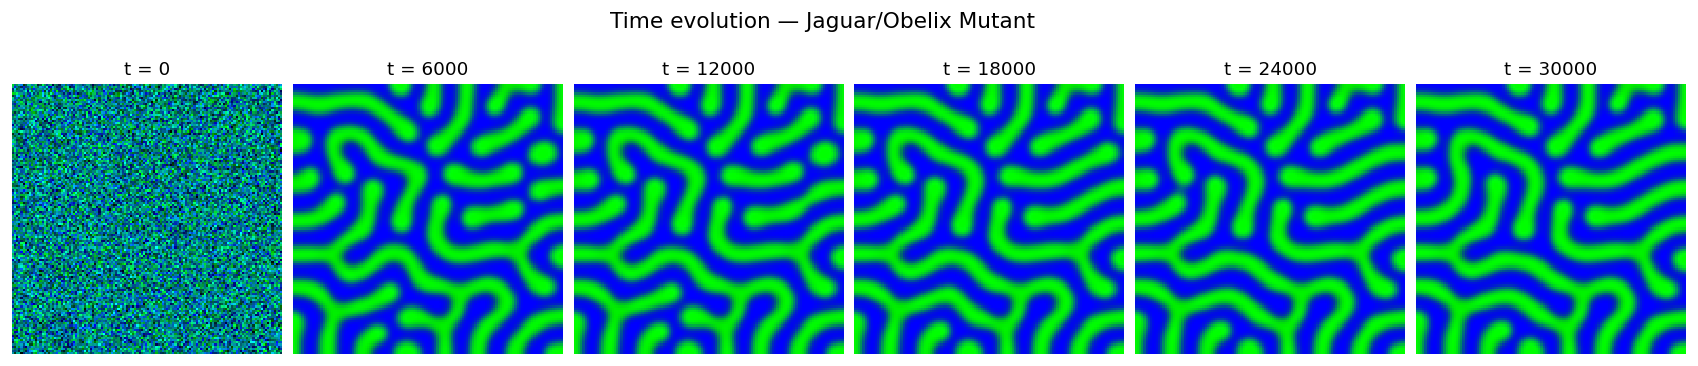

Saved  evolution_jaguar_obelix_mutant.png


In [12]:
for sim in ALL_SIMS:
    name = sim["params"]["name"].lower().replace("/", "_").replace(" ", "_")
    fig  = plot_time_evolution(sim, n_panels=6,
                               save_path=f"evolution_{name}.png")
    plt.show()
    print(f"Saved  evolution_{name}.png")

## Cell 12 — Concentration histograms

A **bimodal distribution** at $T_{\rm final}$ is the signature of stripe / spot
segregation: one peak near $u^*$ (mixed regions) and a second peak either
near 0 or near $U/c_u$ (depleted or saturated regions).

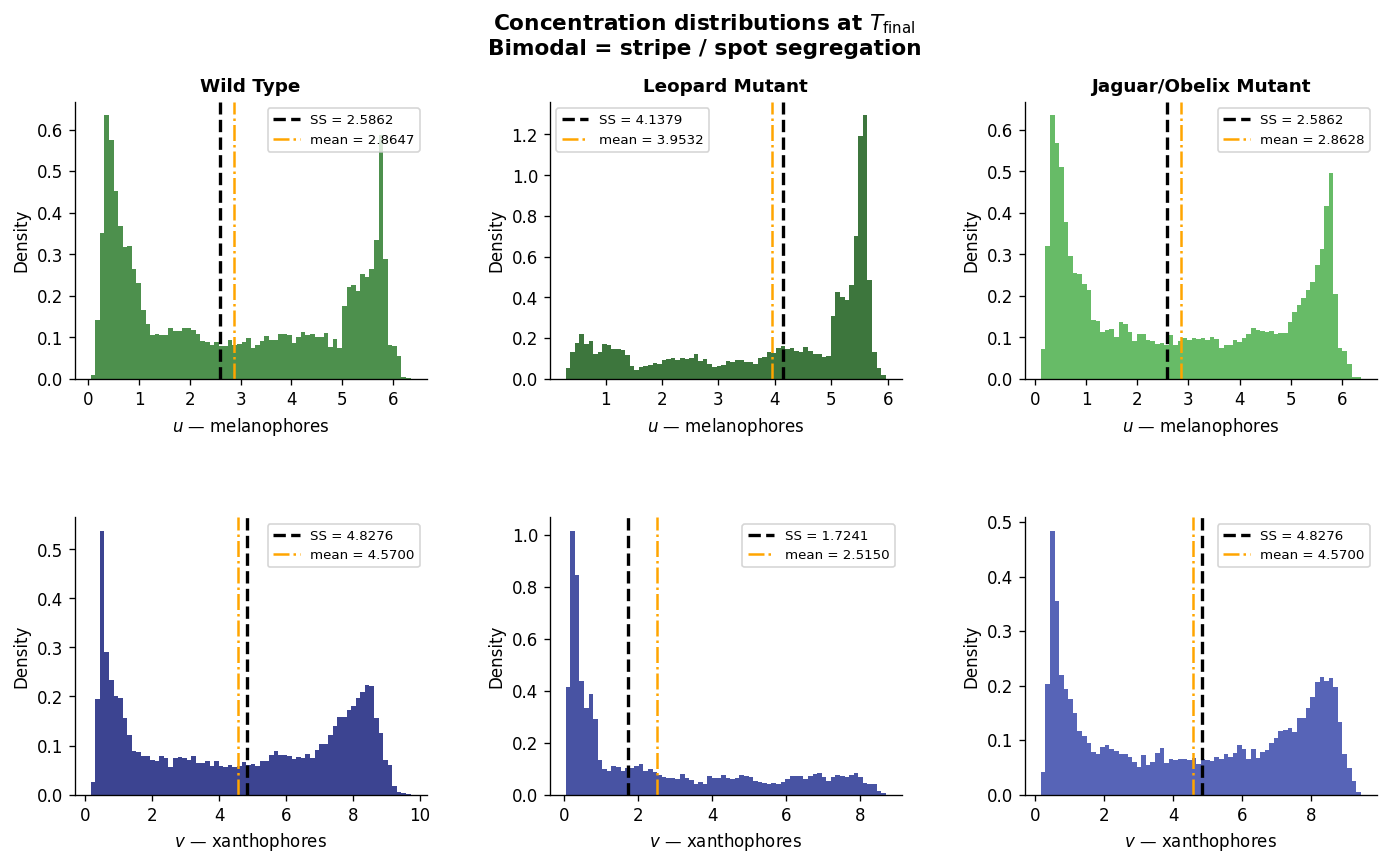

Saved  histograms_kondo2009.png


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5),
                         gridspec_kw={"hspace": 0.50, "wspace": 0.35})

g_colours = ["#2e7d2e", "#1b5e1b", "#4caf4c"]
b_colours = ["#1a237e", "#283593", "#3949ab"]

for col_i, sim in enumerate(ALL_SIMS):
    u_f = sim["final"]["u"].ravel()
    v_f = sim["final"]["v"].ravel()
    ss  = sim["ss"]
    name = sim["params"]["name"]

    for row_i, (field, s_val, label, colours) in enumerate([
        (u_f, ss[0], "$u$ — melanophores", g_colours),
        (v_f, ss[1], "$v$ — xanthophores", b_colours),
    ]):
        ax = axes[row_i, col_i]
        ax.hist(field, bins=70, color=colours[col_i], alpha=0.85,
                edgecolor="none", density=True)
        ax.axvline(s_val, color="black", lw=2.0, ls="--",
                   label=f"SS = {s_val:.4f}")
        ax.axvline(field.mean(), color="orange", lw=1.5, ls="-.",
                   label=f"mean = {field.mean():.4f}")
        if row_i == 0:
            ax.set_title(name, fontsize=11, fontweight="bold")
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel("Density", fontsize=10)
        ax.legend(fontsize=8)

fig.suptitle(
    r"Concentration distributions at $T_{\rm final}$"
    "\nBimodal = stripe / spot segregation",
    fontsize=13, fontweight="bold",
)
plt.savefig("histograms_kondo2009.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved  histograms_kondo2009.png")

## Cell 13 — Radially-averaged 2-D power spectra

The peak of the power spectrum of $u$ should align with the dominant
wavenumber $k^*$ predicted by the dispersion relation.

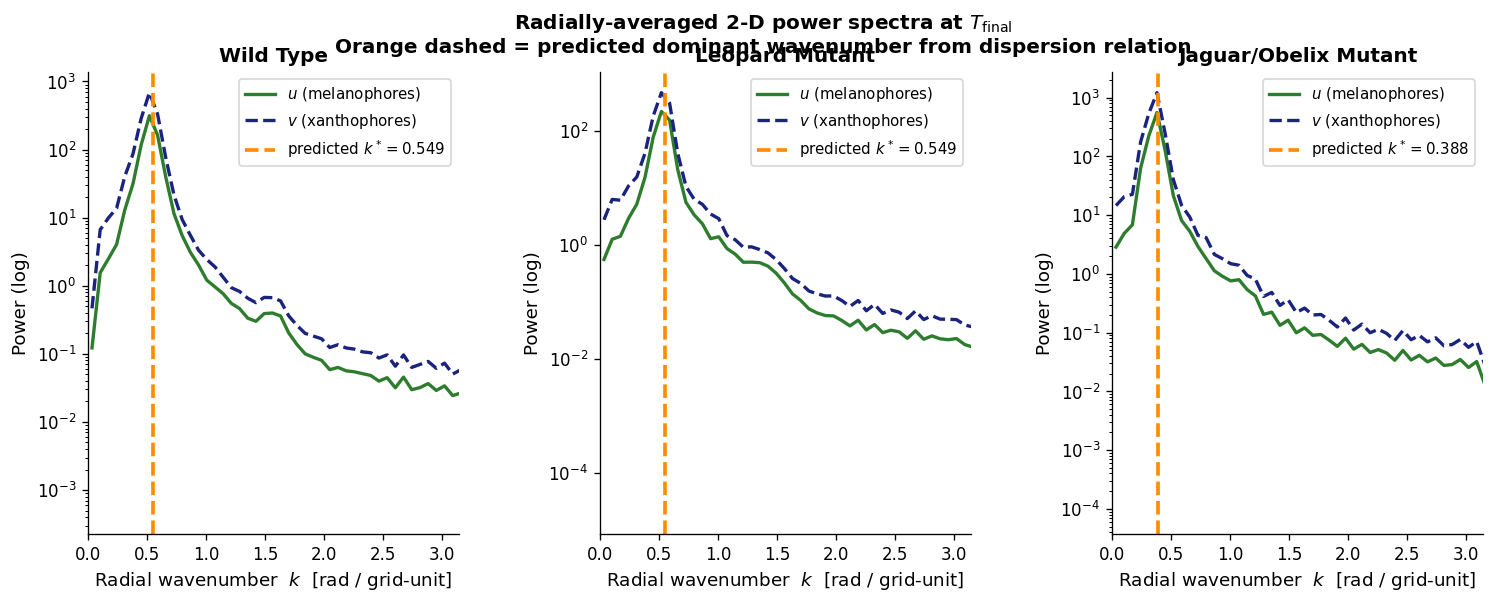

Saved  power_spectra_kondo2009.png


In [14]:
def radial_power_spectrum(field, dx=1.0):
    """
    Compute the radially averaged 2-D power spectrum.

    Returns
    -------
    k_rad : 1-D array  radial wavenumbers in rad / grid-unit
    P_rad : 1-D array  mean power in each annular bin
    """
    ny, nx  = field.shape
    F       = np.fft.fft2(field - field.mean())
    P2      = (np.abs(np.fft.fftshift(F)) ** 2) / (nx * ny)

    kx = np.fft.fftshift(np.fft.fftfreq(nx, d=dx)) * 2.0 * np.pi
    ky = np.fft.fftshift(np.fft.fftfreq(ny, d=dx)) * 2.0 * np.pi
    KX, KY  = np.meshgrid(kx, ky)
    K_mag   = np.sqrt(KX**2 + KY**2)

    n_bins  = nx // 2
    k_bins  = np.linspace(0.0, np.sqrt(2.0) * np.pi, n_bins + 1)
    k_rad   = 0.5 * (k_bins[:-1] + k_bins[1:])
    P_rad   = np.zeros(n_bins)

    for i in range(n_bins):
        mask = (K_mag >= k_bins[i]) & (K_mag < k_bins[i + 1])
        if mask.any():
            P_rad[i] = P2[mask].mean()

    return k_rad, P_rad


fig, axes = plt.subplots(1, 3, figsize=(15, 5.0),
                         gridspec_kw={"wspace": 0.38})
ps_colours = ["steelblue", "crimson", "seagreen"]

for ax, sim, col in zip(axes, ALL_SIMS, ps_colours):
    name = sim["params"]["name"]
    k_u, P_u = radial_power_spectrum(sim["final"]["u"])
    k_v, P_v = radial_power_spectrum(sim["final"]["v"])

    # prevent log(0)
    P_u = np.maximum(P_u, 1e-30)
    P_v = np.maximum(P_v, 1e-30)

    ax.semilogy(k_u, P_u, color="#2e7d2e", lw=2.0, label="$u$ (melanophores)")
    ax.semilogy(k_v, P_v, color="#1a237e", lw=2.0, label="$v$ (xanthophores)",
                ls="--")

    # overlay predicted k*
    res = DISP[name]
    if res["k_peak"] is not None:
        ax.axvline(res["k_peak"], color="darkorange", lw=2.2, ls="--",
                   label=f"predicted $k^*={res['k_peak']:.3f}$")

    ax.set_xlim(0, np.pi)
    ax.set_xlabel(r"Radial wavenumber  $k$  [rad / grid-unit]", fontsize=11)
    ax.set_ylabel("Power (log)", fontsize=11)
    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.legend(fontsize=9)

fig.suptitle(
    r"Radially-averaged 2-D power spectra at $T_{\rm final}$"
    "\nOrange dashed = predicted dominant wavenumber from dispersion relation",
    fontsize=12, fontweight="bold",
)
plt.savefig("power_spectra_kondo2009.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved  power_spectra_kondo2009.png")

## Cell 14 — All three fields at $T_{\rm final}$

Shows $u$, $v$, and $w$ individually to verify that the long-range factor $w$
mirrors $u$ (as expected: $H$ is produced by $u$) and has a smoother spatial
profile due to its higher diffusion coefficient.

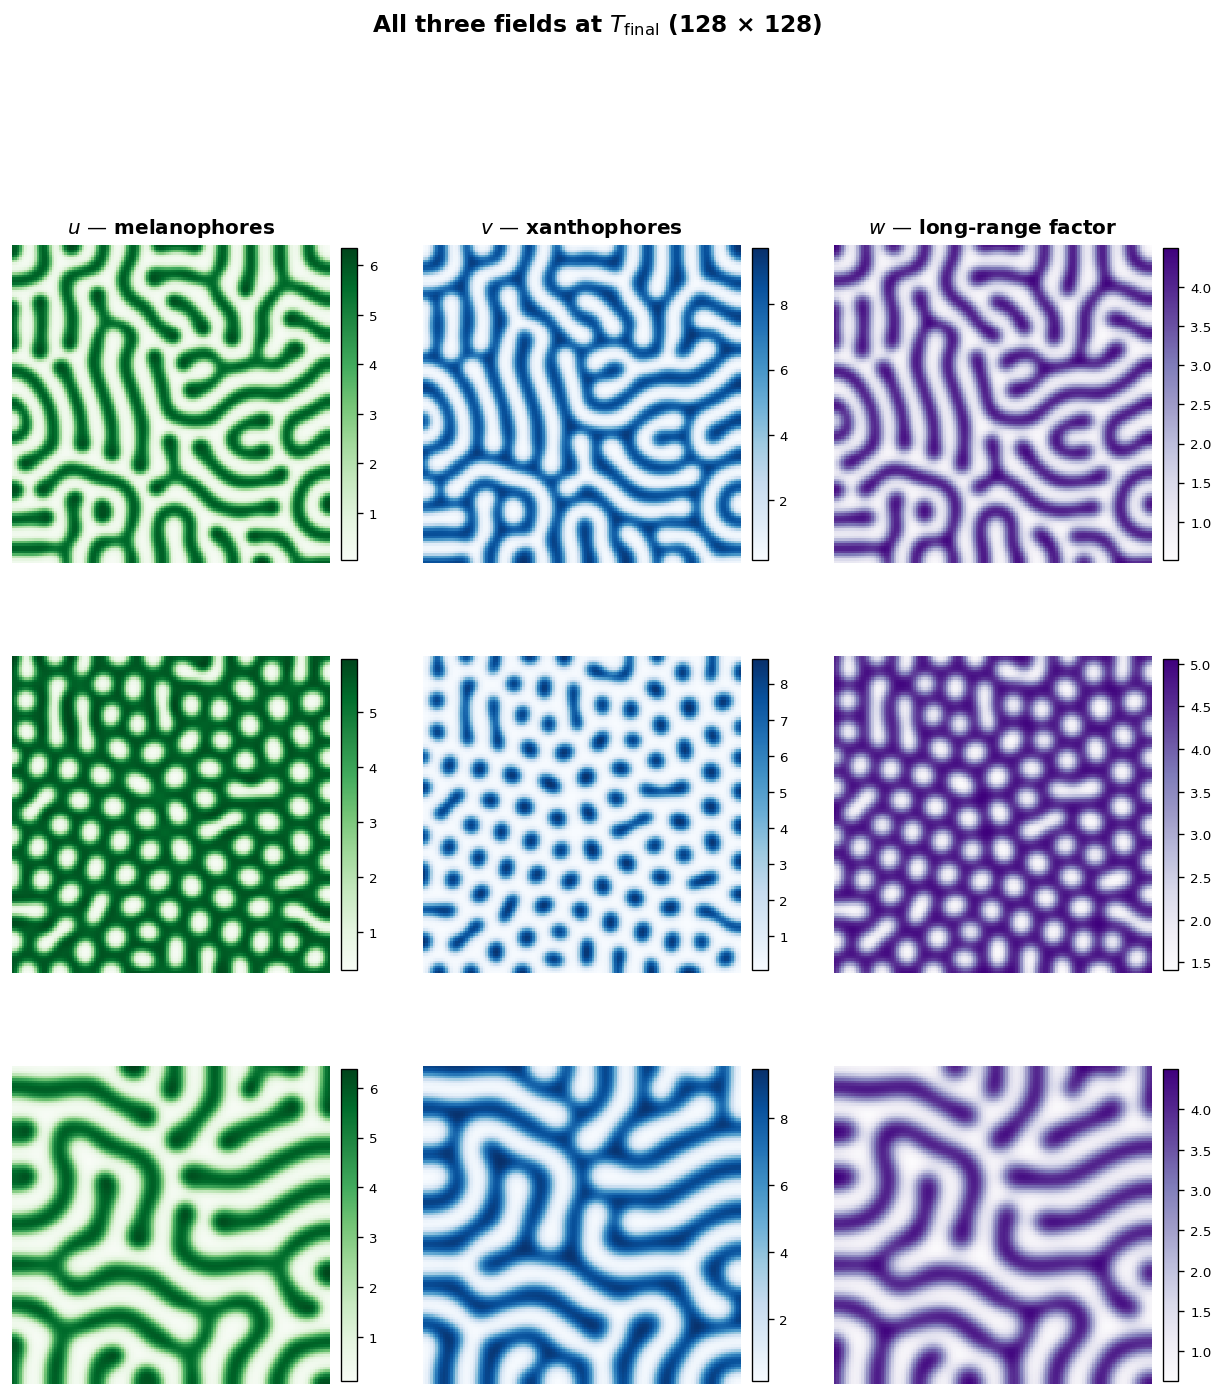

Saved  all_fields_kondo2009.png


In [15]:
fig, axes = plt.subplots(3, 3, figsize=(13, 13),
                         gridspec_kw={"hspace": 0.08, "wspace": 0.06})

field_labels = [
    ("$u$ — melanophores", "Greens"),
    ("$v$ — xanthophores", "Blues"),
    ("$w$ — long-range factor", "Purples"),
]

for row_i, sim in enumerate(ALL_SIMS):
    fields = [sim["final"]["u"], sim["final"]["v"], sim["final"]["w"]]
    for col_i, (field, (flabel, cmap)) in enumerate(zip(fields, field_labels)):
        ax = axes[row_i, col_i]
        im = ax.imshow(field, cmap=cmap, origin="lower",
                       aspect="equal", interpolation="nearest")
        cb = plt.colorbar(im, ax=ax, shrink=0.82, pad=0.03)
        cb.ax.tick_params(labelsize=8)
        if row_i == 0:
            ax.set_title(flabel, fontsize=12, fontweight="bold", pad=7)
        if col_i == 0:
            ax.set_ylabel(sim["params"]["name"],
                          fontsize=11, fontweight="bold", labelpad=8)
        ax.axis("off")

fig.suptitle(r"All three fields at $T_{\rm final}$ (128 × 128)",
             fontsize=14, fontweight="bold", y=1.01)
plt.savefig("all_fields_kondo2009.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved  all_fields_kondo2009.png")

## Cell 15 — Summary statistics

In [16]:
print("=" * 72)
print("  SUMMARY STATISTICS AT T_FINAL")
print("=" * 72)

stat_col_w = 16
hdr = (f"  {'Quantity':<28}"
       + "".join(f"{p['name']:>{stat_col_w}}" for p in ALL_PARAMS))
print(hdr)
print("  " + "─" * (28 + stat_col_w * len(ALL_PARAMS)))

def row(label, values, fmt=".5f"):
    vals_str = "".join(f"{v:{stat_col_w}{fmt}}" for v in values)
    print(f"  {label:<28}{vals_str}")

row("u* (SS value)",
    [sim["ss"][0] for sim in ALL_SIMS])
row("v* (SS value)",
    [sim["ss"][1] for sim in ALL_SIMS])
row("u  mean (final)",
    [sim["final"]["u"].mean() for sim in ALL_SIMS])
row("u  std  (final)",
    [sim["final"]["u"].std()  for sim in ALL_SIMS])
row("v  mean (final)",
    [sim["final"]["v"].mean() for sim in ALL_SIMS])
row("v  std  (final)",
    [sim["final"]["v"].std()  for sim in ALL_SIMS])
row("corr(u, v) final",
    [np.corrcoef(sim["final"]["u"].ravel(),
                 sim["final"]["v"].ravel())[0, 1]
     for sim in ALL_SIMS])
row("k* (predicted)",
    [DISP[p["name"]]["k_peak"] or 0.0 for p in ALL_PARAMS])
row("λ* (predicted)",
    [DISP[p["name"]]["lam_dom"] or 0.0 for p in ALL_PARAMS], ".2f")
row("σ* (peak growth)",
    [DISP[p["name"]]["s_peak"] or 0.0 for p in ALL_PARAMS], ".7f")

print()
print("  Note: corr(u, v) < 0 expected — melanophores and xanthophores")
print("        occupy complementary spatial domains (anti-correlated).")

  SUMMARY STATISTICS AT T_FINAL
  Quantity                           Wild Type  Leopard MutantJaguar/Obelix Mutant
  ────────────────────────────────────────────────────────────────────────────
  u* (SS value)                        2.58621         4.13793         2.58621
  v* (SS value)                        4.82759         1.72414         4.82759
  u  mean (final)                      2.86468         3.95323         2.86277
  u  std  (final)                      2.07438         1.77706         2.07009
  v  mean (final)                      4.56996         2.51501         4.56998
  v  std  (final)                      3.05861         2.58664         3.06024
  corr(u, v) final                    -0.99581        -0.99626        -0.99576
  k* (predicted)                       0.54875         0.54875         0.38750
  λ* (predicted)                         11.45           11.45           16.21
  σ* (peak growth)                   0.0045559       0.0045559       0.0045559

  Note: corr(u,

## Summary

### ✓  Steady-state stability (k = 0)
All three parameter sets satisfy the **Routh–Hurwitz conditions**:
every eigenvalue of the reaction Jacobian $J$ has strictly negative real
part.  The homogeneous steady states are **stable in the absence of
diffusion** for all three variants.

### ✓  Turing instability
The dispersion relation $\sigma(k)$ is negative at $k=0$ but rises above
zero for a band of wavenumbers around $k^*>0$: diffusion
**destabilises** short-range modes even though it stabilises the
homogeneous background.  This is the classical **Turing (diffusion-driven)
instability**.

### ✓  Simulations reproduce Figure 4
| Variant | Pattern | Mechanism |
|---------|---------|-----------|
| Wild type | stripes | balanced short/long range |
| Leopard mutant | spots | increased $c_3$ raises $u$-production, shifts topology |
| Jaguar/Obelix | wider stripes | doubled $D$ shifts $k^*$ lower → larger $\lambda^*$ |

The dominant wavenumber measured from the final-state **power spectrum**
matches the $k^*$ predicted by the linear dispersion relation to within
the discrete grid resolution.